# How the cell-cycle model works

The [cell-cycle tutorial](cell_cycle.ipynb) shows how to call {func}`~mantispy.tl.fit_cell_cycle`,
{func}`~mantispy.tl.project_cell_cycle` and {func}`~mantispy.tl.phase_order`, and how to read what they write. This
notebook explains each step of the model with a figure. Most figures use small simulated populations, where the true
cycle position of every cell is known, so each step can be checked against the truth. Real cells from the optical
pooled screen appear only where they show something a simulation cannot. Most numbers come from what the public
functions write, and the posterior curves and the smoothing sketch re-derive the same steps in a few lines.

In [1]:
import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import mantispy as mt

plt.rcParams["figure.dpi"] = 110


def simulate(n_cells=6000, background=0.0, seed=0, reverse_at=None):
    """A growing population: G1 until 0.45 of the cycle, S until 0.75, then G2M, with DNA doubling through S.

    With ``reverse_at``, tubulin falls back after that age, as a feature that reverses in mitosis would.
    """
    rng = np.random.default_rng(seed)
    age = -np.log2(1 - rng.random(n_cells) / 2)  # the age distribution of a growing population
    progress = np.clip((age - 0.45) / 0.3, 0, 1)  # how far replication has gone
    amount = 1 + progress  # DNA amount, 1 in G1 and 2 in G2M
    integrated = 1000 * amount * 2 ** rng.normal(0, 0.04, n_cells) + background
    rise = np.clip(age - 0.45, 0, None)
    if reverse_at is not None:
        rise = np.where(age > reverse_at, 2 * (reverse_at - 0.45) - rise, rise)
    tubulin = 1 + 2 * rise + rng.normal(0, 0.03, n_cells)  # rises from S onwards
    size = rng.normal(0, 0.25, n_cells)  # how large a cell is, unrelated to its age
    area = 1000 * 2 ** (0.8 * age + size)
    solidity = np.clip(rng.normal(0.975, 0.004, n_cells), 0, 1)
    noise = rng.normal(0, 1, (n_cells, 4))
    names = [
        "Nuclei_Intensity_IntegratedIntensity_DNA",
        "Cells_Intensity_MeanIntensity_Tubulin",
        "Nuclei_AreaShape_Area",
        "Nuclei_AreaShape_Solidity",
    ] + [f"Cells_Texture_Noise_{i}" for i in range(4)]
    obs = pd.DataFrame(
        {
            "Metadata_Plate": "P1",
            "Metadata_Well": [f"W{i % 4}" for i in range(n_cells)],
            "Metadata_Control_Type": "negcon",
            "age": age,
            "size": size,
            "true_phase": np.where(age < 0.45, "G1", np.where(age < 0.75, "S", "G2M")),
        },
        index=[str(i) for i in range(n_cells)],
    )
    X = np.column_stack([integrated, tubulin, area, solidity, noise])
    var = pd.DataFrame({"channel": ["DNA", "Tubulin", "", "", "", "", "", ""]}, index=names)
    return ad.AnnData(X=X, obs=obs, var=var)


def template(model, grid):
    """The DNA content the model expects at each cycle position: flat at 2N, a linear rise in DNA amount, flat at 4N."""
    low, high = model["peaks"]
    edges = model["edges"]
    progress = np.clip((grid - edges[1]) / (edges[2] - edges[1]), 0, 1)
    return np.log2(2.0**low + (2.0**high - 2.0**low) * progress)


def age_at(share):
    """The cycle position of the cell at a cumulative share of a growing population."""
    return -np.log2(1 - share / 2)


GRID = (np.arange(400) + 0.5) / 400
PRIOR = 2 * np.log(2) * 2.0**-GRID  # the age density of a growing population

## The input: DNA content

The model reads one number per cell, the integrated intensity of its DNA stain. {func}`~mantispy.tl.dna_content` takes its
log2 and subtracts the log2 of the G1 peak, so a G1 cell sits near 0 and a cell with twice the DNA near 1. The unit is
a doubling.

A doubling of DNA gives 1 only if the intensity is proportional to the DNA. A constant background added to every
nucleus breaks that. With a G1 intensity a and a background b, the 4N peak sits at the log2 of (2a + b) / (a + b),
which is below 1. The two simulations
below differ only in a background of a fifth of the G1 intensity.

no background: 4N peak near 0.99
background of 200: 4N peak near 0.87


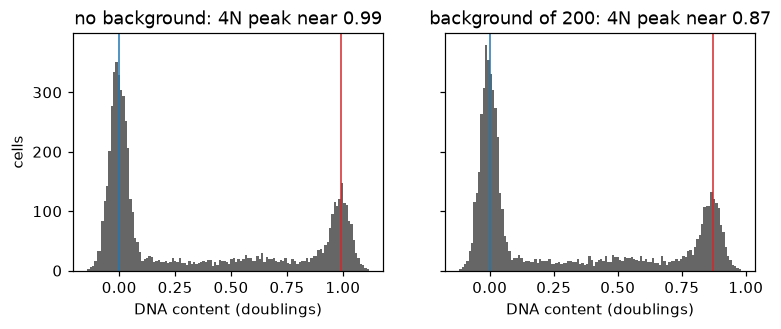

expected 4N position with background: 0.87


In [2]:
clean, shifted = simulate(), simulate(background=200.0)
figure, axes = plt.subplots(1, 2, figsize=(8, 2.8), sharey=True)
for axis, cells, title in zip(axes, (clean, shifted), ("no background", "background of 200"), strict=True):
    mt.tl.dna_content(cells, dna_feature="Nuclei_Intensity_IntegratedIntensity_DNA", reference="negcon")
    content = cells.obs["Metadata_DNAContent"]
    peak = content[content > 0.6].round(2).mode().iloc[0]
    axis.hist(content, bins=120, color="0.4")
    axis.axvline(0, color="tab:blue", lw=1)
    axis.axvline(peak, color="tab:red", lw=1)
    axis.set(title=f"{title}: 4N peak near {peak:.2f}", xlabel="DNA content (doublings)")
    print(f"{title}: 4N peak near {peak:.2f}")
axes[0].set_ylabel("cells")
plt.show()
print("expected 4N position with background:", round(np.log2(2200 / 1200), 2))

Without background the 4N peak sits near 0.99. With a background of a fifth of the G1 intensity it sits near
0.87, as the formula gives. The model reads the 4N peak from the data, so it follows such a shift.

## The template

The model describes the DNA content a cell should have at each point of its cycle. Through G1 it is flat at the 2N
peak. Through S, DNA is copied at a steady rate, so the amount of DNA, not its logarithm, rises along a straight line.
Through G2 and mitosis it is flat at the 4N peak, and at division it drops back to 2N, where the next cycle starts.
The model takes both peaks from the data rather than assuming 0 and 1.

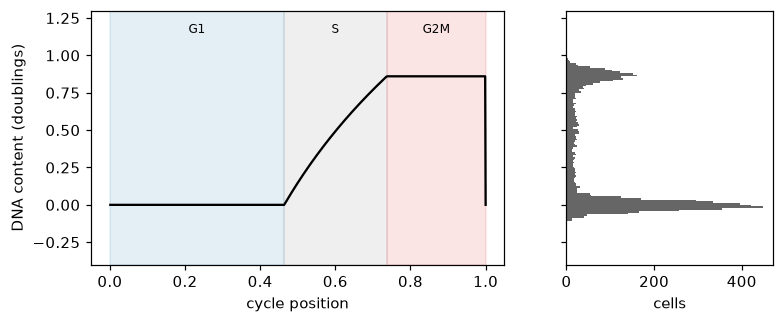

2N peak          0.000
4N peak          0.860
2N peak width    0.039
dtype: float64

In [3]:
cells = shifted
mt.tl.fit_cell_cycle(cells, reference="negcon", qc_features=("Nuclei_AreaShape_Area", "Nuclei_AreaShape_Solidity"))
model = cells.uns["mantispy"]["cell_cycle"]
expected, edges = template(model, GRID), model["edges"]
figure, (left, right) = plt.subplots(1, 2, figsize=(8, 3), sharey=True, gridspec_kw={"width_ratios": [2, 1]})
for (start, end), name, color in zip(
    zip(edges[:-1], edges[1:], strict=True), ("G1", "S", "G2M"), ("tab:blue", "tab:grey", "tab:red"), strict=True
):
    left.axvspan(start, end, color=color, alpha=0.12)
    left.text((start + end) / 2, 1.15, name, ha="center", fontsize=8)
left.plot(np.r_[GRID, 1.0], np.r_[expected, expected[0]], color="black")
left.set(xlabel="cycle position", ylabel="DNA content (doublings)", ylim=(-0.4, 1.3))
right.hist(cells.obs["Metadata_DNAContent"], bins=100, orientation="horizontal", color="0.4")
right.set(xlabel="cells")
plt.show()
pd.Series({"2N peak": model["peaks"][0], "4N peak": model["peaks"][1], "2N peak width": model["sd"]}).round(3)

In the simulation with background, the 2N peak sits at 0.000 and the 4N peak at 0.860, and the 2N peak width is
0.039 doublings, close to the 0.04 the simulation added. Through S the template curves, because a straight rise in
the amount of DNA is a curve in its logarithm. The histogram beside it shows the cells piled on the two flat parts.

## Ergodic rate analysis: from shares of cells to time

The fit gives the share of control cells in G1, S and G2M. Turning shares into time needs one fact about a growing
population {cite:p}`Kafri_2013`. Every division turns one old cell into two young ones, so in steady state young
cells outnumber old ones, and the density of cells of age t, as a share of the cycle, is 2 ln 2 times 2 to the power
-t. The share of cells younger than t is then F = 2(1 - 2^-t), so a cumulative share F corresponds to the age
t = -log2(1 - F/2). Reading the shares directly as time would make G1 look longer than it is.

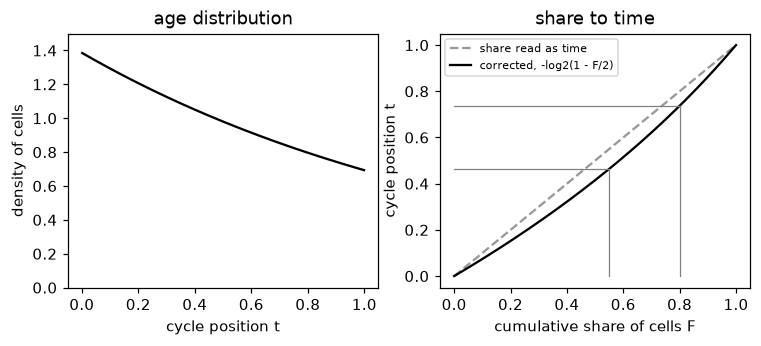

,fitted share of cells,true share of cells,share of the cycle,true share of the cycle
G1,0.55,0.536,0.464,0.45
S,0.25,0.272,0.273,0.30
G2M,0.20,0.192,0.263,0.25


In [4]:
share = np.linspace(0, 1, 201)
figure, (left, right) = plt.subplots(1, 2, figsize=(8, 3))
left.plot(GRID, PRIOR, color="black")
left.set(xlabel="cycle position t", ylabel="density of cells", title="age distribution", ylim=(0, 1.5))
right.plot(share, share, color="0.6", ls="--", label="share read as time")
right.plot(share, age_at(share), color="black", label="corrected, -log2(1 - F/2)")
cumulative = np.cumsum(model["fractions"])[:2]
for value in cumulative:
    right.plot([value, value], [0, age_at(value)], color="tab:grey", lw=0.8)
    right.plot([0, value], [age_at(value), age_at(value)], color="tab:grey", lw=0.8)
right.set(xlabel="cumulative share of cells F", ylabel="cycle position t", title="share to time")
right.legend(fontsize=7)
plt.show()
truth = cells.obs["true_phase"].value_counts(normalize=True)
pd.DataFrame(
    {
        "fitted share of cells": model["fractions"],
        "true share of cells": [truth["G1"], truth["S"], truth["G2M"]],
        "share of the cycle": np.diff(model["edges"]),
        "true share of the cycle": [0.45, 0.30, 0.25],
    },
    index=["G1", "S", "G2M"],
).round(3)

The fitted shares of cells, 0.55, 0.25 and 0.20, are close to the true shares of 0.536, 0.272 and 0.192. After
the correction, the shares of the cycle come out as 0.464, 0.273 and 0.263, against the 0.45, 0.30 and 0.25 the
simulation used. Read directly as time, the shares of cells would have given G1 55% of the cycle instead of about
45%.

## The posterior for one cell

{func}`~mantispy.tl.project_cell_cycle` asks, for each cell, how probable each cycle position is given its DNA
content. The posterior combines a likelihood and a prior. The likelihood says how well the cell's DNA content fits the template at each position,
with the 2N peak width as the measurement noise. The prior is the age distribution above. Their product, normalized,
is the posterior. The cells below sit in G1, in the middle of S and in G2M.

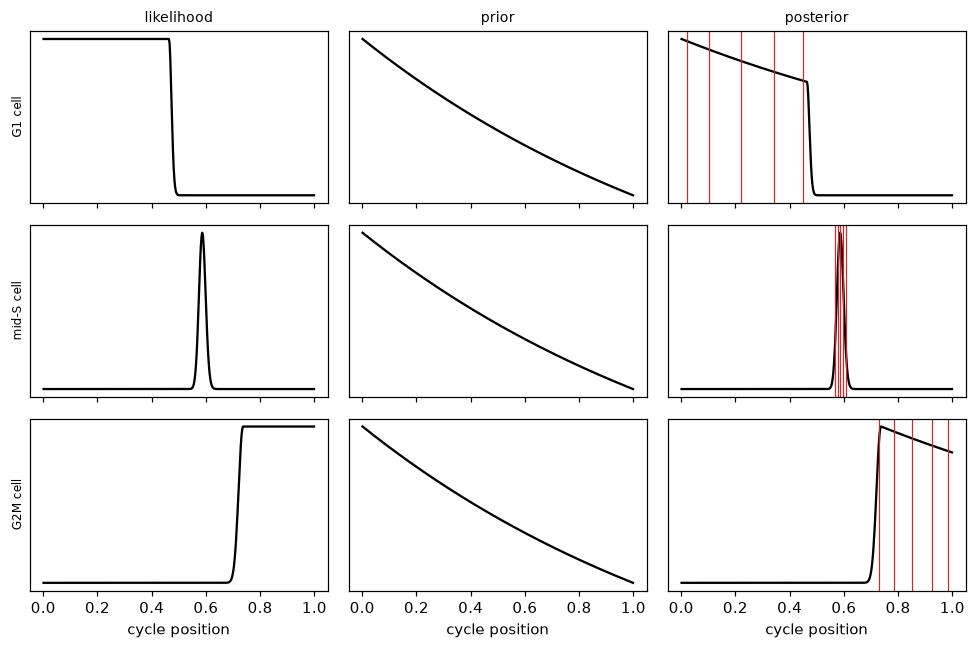

,G1,S,G2M,sub-2N,above-4N,5%,25%,50%,75%,95%
G1 cell,0.98,0.02,0.00,0.0,0.0,0.02,0.10,0.22,0.34,0.45
mid-S cell,0.00,1.00,0.00,0.0,0.0,0.57,0.58,0.59,0.60,0.61
G2M cell,0.00,0.08,0.92,0.0,0.0,0.73,0.78,0.85,0.92,0.98


In [5]:
examples = pd.Series({"G1 cell": 0.0, "mid-S cell": 0.45, "G2M cell": model["peaks"][1]})
probe = ad.AnnData(obs=pd.DataFrame({"Metadata_DNAContent": examples.to_numpy()}, index=list(examples.index)))
dna_only = {name: value for name, value in model.items() if name != "qc"}  # the probes carry no shape features
mt.tl.project_cell_cycle(probe, model=dna_only, by=None)

figure, axes = plt.subplots(3, 3, figsize=(9, 6), sharex=True)
for row, (name, content) in enumerate(examples.items()):
    likelihood = np.exp(-0.5 * ((content - expected) / model["sd"]) ** 2)
    prior = PRIOR
    posterior = likelihood * prior / (likelihood * prior).sum()
    for column, (curve, title) in enumerate(((likelihood, "likelihood"), (prior, "prior"), (posterior, "posterior"))):
        axes[row, column].plot(GRID, curve, color="black")
        axes[row, column].set_yticks([])
        if row == 0:
            axes[row, column].set_title(title, fontsize=9)
    for q in probe.obsm["cell_cycle_quantiles"].loc[name]:
        axes[row, 2].axvline(q, color="tab:red", lw=0.8)
    axes[row, 0].set_ylabel(name, fontsize=8)
for axis in axes[-1]:
    axis.set_xlabel("cycle position")
plt.tight_layout()
plt.show()
pd.concat([probe.obsm["cell_cycle_probabilities"], probe.obsm["cell_cycle_quantiles"]], axis=1).round(2)

For the G1 cell, the likelihood is flat across all of G1, since every G1 position predicts the same DNA, so the
posterior is the prior cut off at the end of G1. Its 5% to 95% quantiles span 0.02 to 0.45. The mid-S cell's DNA
fits only a narrow stretch of S, and its quantiles span 0.57 to 0.61. The G2M cell spreads over G2M, from 0.73 to
0.98. The phase probabilities follow, at 0.98 for G1, 1.00 for S and 0.92 for G2M, with the rest on the neighboring
phase.

Summing the posterior over each phase gives the phase probabilities. Drawn against DNA content, they show where one
phase gives way to the next, and where a cell becomes more likely to sit below 2N or above 4N, off the cycle, than
on it.

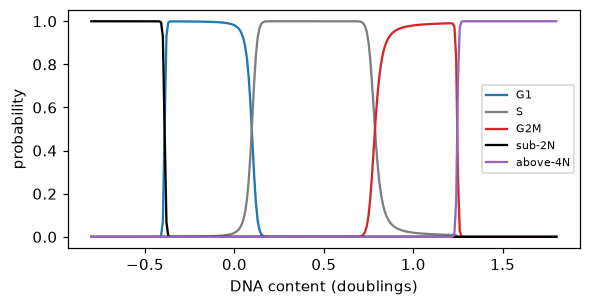

sub-2N below -0.4 and above-4N above 1.25


In [6]:
grid = np.linspace(-0.8, 1.8, 261)
probe = ad.AnnData(obs=pd.DataFrame({"Metadata_DNAContent": grid}, index=[str(i) for i in range(grid.size)]))
mt.tl.project_cell_cycle(probe, model=dna_only, by=None)
probabilities = probe.obsm["cell_cycle_probabilities"]
figure, axis = plt.subplots(figsize=(6, 2.8))
for phase, color in zip(probabilities.columns, ("tab:blue", "tab:grey", "tab:red", "black", "tab:purple"), strict=True):
    axis.plot(grid, probabilities[phase], color=color, label=phase)
axis.set(xlabel="DNA content (doublings)", ylabel="probability")
axis.legend(fontsize=7)
plt.show()
below, above = probabilities["sub-2N"] > 0.5, probabilities["above-4N"] > 0.5
print("sub-2N below", round(grid[below].max(), 2), "and above-4N above", round(grid[above].min(), 2))

G1 gives way to S, and S to G2M, where the template leaves each peak. The change is as sharp as the 2N peak is
narrow. Below -0.4 doublings the flat background becomes the most probable component and a cell is called sub-2N, and above 1.25 it is called
above-4N.

## The check before the fit

A model of the cycle only makes sense for a reference that cycles. Before fitting, the DNA content of the reference
must show a 2N peak, a separate 4N peak, a valley between them that S cells fill, and a share of cells in S. Three
populations that do not cycle fail it. They are a narrow line of DNA content just above 2N, a single 2N blob, and two clusters
at 2N and 4N with nothing between them.

fit_cell_cycle: the reference does not show separate 2N and 4N peaks with S cells between them {'is_peak': False, 'peak_ratio': 0.0, 'valley_ratio': 1.376786134312392e+21, 's_floor': 0.0, 's_share': 0.014}; project_cell_cycle will give NaN


fit_cell_cycle: the reference does not show separate 2N and 4N peaks with S cells between them {'is_peak': False, 'peak_ratio': 0.0, 'valley_ratio': inf, 's_floor': nan, 's_share': 0.0}; project_cell_cycle will give NaN


fit_cell_cycle: the reference does not show separate 2N and 4N peaks with S cells between them {'is_peak': True, 'peak_ratio': 0.727, 'valley_ratio': 0.0, 's_floor': 0.0, 's_share': 0.014}; project_cell_cycle will give NaN


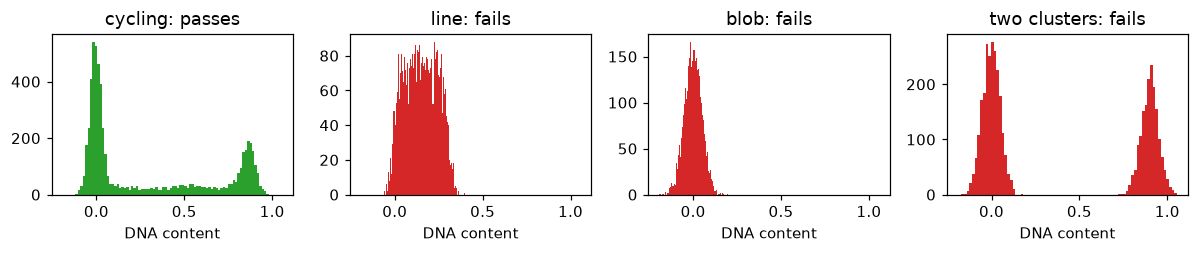

,a 4N peak,4N peak at least a twentieth of the 2N peak,valley at most nine tenths of the 4N peak,S density at least a tenth of the 4N peak,at least 3% of cells in S,passes
cycling,True,True,True,True,True,True
line,False,False,False,False,False,False
blob,False,False,False,False,False,False
two clusters,True,True,True,False,False,False


In [7]:
rng = np.random.default_rng(1)
populations = {
    "cycling": cells.obs["Metadata_DNAContent"].to_numpy(),
    "line": rng.uniform(0, 0.3, 4000) + rng.normal(0, 0.03, 4000),
    "blob": rng.normal(0, 0.05, 4000),
    "two clusters": (rng.random(4000) < 0.4) * 0.9 + rng.normal(0, 0.05, 4000),
}
figure, axes = plt.subplots(1, 4, figsize=(11, 2.4), sharex=True)
report = {}
for axis, (name, content) in zip(axes, populations.items(), strict=True):
    population = ad.AnnData(
        obs=pd.DataFrame({"Metadata_DNAContent": content}, index=[str(i) for i in range(content.size)])
    )
    mt.tl.fit_cell_cycle(population, reference=None)
    fitted = population.uns["mantispy"]["cell_cycle"]
    report[name] = {**fitted["check"], "passed": fitted["passed"]}
    axis.hist(content, bins=80, color="tab:green" if fitted["passed"] else "tab:red")
    axis.set(title=f"{name}: {'passes' if fitted['passed'] else 'fails'}", xlabel="DNA content")
plt.tight_layout()
plt.show()
pd.DataFrame(
    {
        "a 4N peak": [r["is_peak"] for r in report.values()],
        "4N peak at least a twentieth of the 2N peak": [r["peak_ratio"] >= 0.05 for r in report.values()],
        "valley at most nine tenths of the 4N peak": [r["valley_ratio"] <= 0.9 for r in report.values()],
        "S density at least a tenth of the 4N peak": [r["s_floor"] >= 0.1 for r in report.values()],
        "at least 3% of cells in S": [r["s_share"] >= 0.03 for r in report.values()],
        "passes": [r["passed"] for r in report.values()],
    },
    index=list(report),
)

The cycling population passes every criterion. The line and the blob fail every criterion, since neither has a
4N peak, and fewer than 3% of their cells sit in S. The two clusters have both peaks and a deep valley between them, but nothing fills S, so they
fail on the density across S and on the share of cells in S.

## Off the cycle, and nuclei that are not single cells

The model holds a flat background for cells that fit no part of the cycle, and its weight is fitted with the rest.
The background below the middle of the cycle holds sub-2N cells, and above it cells beyond 4N. DNA content alone
cannot see two other problems. Two touching G1 nuclei segmented as one hold 4N and look like a G2M cell, and a
fragment of a dying cell holds less than 2N. With ``qc_features``, the fit learns from the controls how
small and how irregular a nucleus may be, and flags nuclei beyond that. Below, the simulation gains 150 merged pairs
of G1 nuclei and 150 fragments.

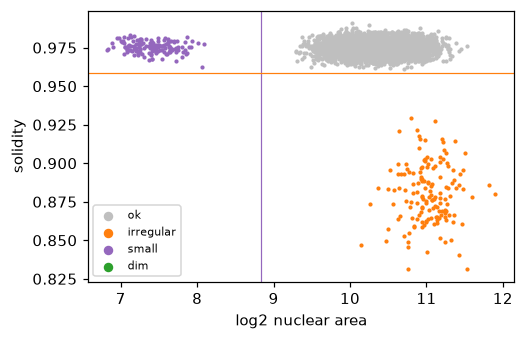

cell_cycle_phase G1  S G2M           sub-2N  above-4N
cell_cycle_qc    ok ok  ok irregular  small irregular
true_phase                                           
merged pair       0  0   0       149      0         1
fragment          0  0   0         0    150         0

In [8]:
rng = np.random.default_rng(2)
base = simulate(seed=3)
g1 = np.flatnonzero(base.obs["true_phase"] == "G1")[:300]
merged, fragments = base[g1[:150]].copy(), base[g1[150:]].copy()
merged.X[:, 0] *= 2
merged.X[:, 2] *= 1.8
merged.X[:, 3] = rng.normal(0.88, 0.02, 150)
fragments.X[:, 0] *= 0.35
fragments.X[:, 2] *= 0.15
merged.obs["true_phase"], fragments.obs["true_phase"] = "merged pair", "fragment"
merged.obs_names = [f"m{i}" for i in range(150)]
fragments.obs_names = [f"f{i}" for i in range(150)]
mixed = ad.concat([base, merged, fragments], merge="same")
mt.tl.dna_content(mixed, dna_feature="Nuclei_Intensity_IntegratedIntensity_DNA", reference="negcon")
mt.tl.fit_cell_cycle(mixed, reference="negcon", qc_features=("Nuclei_AreaShape_Area", "Nuclei_AreaShape_Solidity"))
mt.tl.project_cell_cycle(mixed)

cutoffs = mixed.uns["mantispy"]["cell_cycle"]["qc"]["cutoffs"]
figure, axis = plt.subplots(figsize=(5, 3.2))
for flag, color in zip(
    ("ok", "irregular", "small", "dim"), ("0.75", "tab:orange", "tab:purple", "tab:green"), strict=True
):
    rows = (mixed.obs["cell_cycle_qc"] == flag).to_numpy()
    axis.scatter(np.log2(mixed.X[rows, 2]), mixed.X[rows, 3], s=3, color=color, label=flag, rasterized=True)
axis.axvline(cutoffs[0], color="tab:purple", lw=0.8)
axis.axhline(cutoffs[1], color="tab:orange", lw=0.8)
axis.set(xlabel="log2 nuclear area", ylabel="solidity")
axis.legend(fontsize=7, markerscale=3)
plt.show()
pd.crosstab(mixed.obs["true_phase"], [mixed.obs["cell_cycle_phase"], mixed.obs["cell_cycle_qc"]]).loc[
    ["merged pair", "fragment"]
]

DNA content alone calls 149 of the 150 merged pairs G2M, since they hold 4N, and the shape check flags all 150
as irregular. The 150 fragments sit below 2N, so the model already calls them sub-2N, and the shape check adds the
reason, that they are small. The solidity check also flags mitotic cells, whose condensed chromosomes give an irregular
mask, as [the tutorial](cell_cycle.ipynb#shape-checks) shows on real cells.



## An order within a phase, step by step

DNA content is flat through G1 and G2M, so the model cannot order cells within them. {func}`~mantispy.tl.phase_order`
tries to order the cells of one phase from the other features, without labels. It runs in the steps below, shown for
G2M on a simulation where tubulin rises with progress from S onwards and four features are noise.

### a. An S axis, fitted on the controls

S cells carry their own progress label, their DNA content. On the reference cells on the cycle, the features are
scaled robustly and reduced to up to 30 principal components, and a ridge regression of DNA content on those
components is fitted on the S cells only. The fitted direction is the S axis. Each feature also gets a weight, the
size of its rank correlation with DNA content in S. By default the features exclude those measured on the DNA stain
and the nuclear shape of the DNA mask, so the order cannot read DNA content back.

In [9]:
import warnings

sim = simulate(seed=4)
mt.tl.dna_content(sim, dna_feature="Nuclei_Intensity_IntegratedIntensity_DNA", reference="negcon")
mt.tl.fit_cell_cycle(sim, reference="negcon")
mt.tl.project_cell_cycle(sim, by=None)
mt.tl.phase_order(sim, phase="G2M")
warnings.filterwarnings("ignore", message="phase_order is experimental")  # read once; the later calls repeat it
entry = sim.uns["mantispy"]["cell_cycle_G2M_order"]
pd.Series(entry["weights"], index=entry["features"]).rename("weight").round(3)

<path>:7: UserWarning: phase_order is experimental: validate the order against a marker of the phase or a paired modality before reading it biologically
  mt.tl.phase_order(sim, phase="G2M")


Cells_Intensity_MeanIntensity_Tubulin    0.966
Cells_Texture_Noise_0                    0.033
Cells_Texture_Noise_1                    0.013
Cells_Texture_Noise_2                    0.010
Cells_Texture_Noise_3                    0.004
Name: weight, dtype: float64

Tubulin gets almost all the weight, at 0.97, and the noise features almost none. The nuclear area and solidity are
left out by default, since they come from the DNA mask.

### b. The S axis, carried into the phase

The axis is then carried into the phase, where it was never fitted. The left panel shows it in S, the right in
G2M.

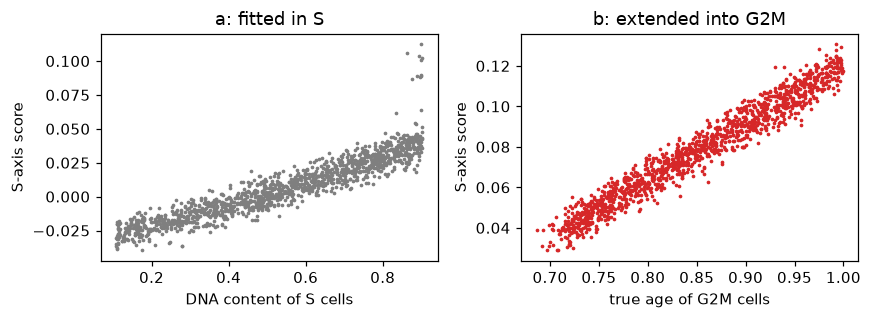

S axis vs DNA content in S: 0.95
S axis vs true age in G2M: 0.98


In [10]:
def s_axis(adata, entry):
    """Each cell's S-axis score and its place in the weighted space, from what phase_order stores."""
    scaled = np.clip(np.nan_to_num((adata[:, entry["features"]].X - entry["median"]) / entry["scale"]), -8, 8)
    centred, components = scaled - entry["mean"], np.asarray(entry["components"])
    return centred @ components.T @ entry["coef"], (centred * entry["weights"]) @ components.T


score, weighted = s_axis(sim, entry)
phase = sim.obs["cell_cycle_phase"].astype(str).to_numpy()
in_s, in_g2m = phase == "S", phase == "G2M"
age = sim.obs["age"].to_numpy()
figure, (left, right) = plt.subplots(1, 2, figsize=(8, 3))
left.scatter(sim.obs["Metadata_DNAContent"][in_s], score[in_s], s=2, color="tab:grey", rasterized=True)
left.set(xlabel="DNA content of S cells", ylabel="S-axis score", title="a: fitted in S")
right.scatter(age[in_g2m], score[in_g2m], s=2, color="tab:red", rasterized=True)
right.set(xlabel="true age of G2M cells", ylabel="S-axis score", title="b: extended into G2M")
plt.tight_layout()
plt.show()
spearman = lambda a, b: pd.Series(np.asarray(a)).corr(pd.Series(np.asarray(b)), method="spearman")
print("S axis vs DNA content in S:", round(spearman(score[in_s], sim.obs["Metadata_DNAContent"][in_s]), 2))
print("S axis vs true age in G2M:", round(spearman(score[in_g2m], age[in_g2m]), 2))

In S the axis tracks DNA content with a rank correlation of 0.95. In G2M it still rises with the true age, at 0.98,
because tubulin keeps rising after S. This step assumes that what changes through S keeps changing in the same
direction through the phase.

### c. A nearest-neighbor graph, and smoothing along it

The reference cells of the phase are placed in the weighted space, where each scaled feature is multiplied by its
weight before the principal axes are applied, so the features that track DNA in S count most. Each cell is linked to
its nearest neighbors there. Each cell starts at its rank on the S axis, and smoothing moves its value toward its
neighbors'. The package solves (I + 10 L) x = start, where L is the Laplacian of the graph, and ranks x from 0 to 1.
The sketch shows 40 cells with 5 neighbors each, before and after. The package uses every reference cell of the phase
and 30 neighbors.

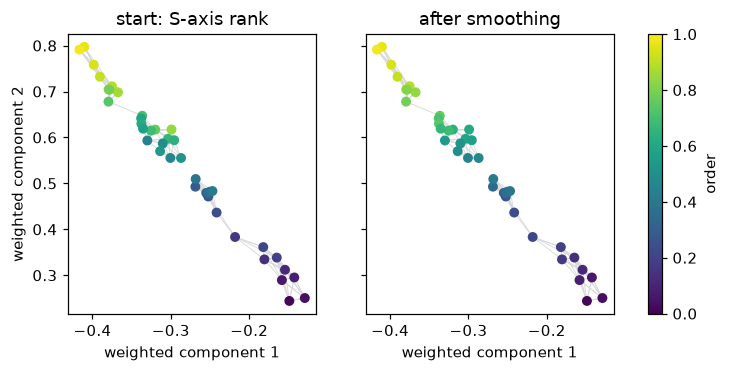

sketch, Spearman with true age: start 0.96 after 0.97


In [11]:
from scipy.sparse import diags, eye
from scipy.sparse.linalg import spsolve
from sklearn.neighbors import kneighbors_graph


def smooth(points, start, k):
    """Solve (I + 10 L) x = start on the symmetric k-nearest-neighbour graph, then rank x from 0 to 1."""
    graph = kneighbors_graph(points, n_neighbors=k)
    affinity = graph.maximum(graph.T) * (np.log2(k) / k)
    laplacian = diags(np.asarray(affinity.sum(axis=1)).ravel()) - affinity
    solved = spsolve((eye(points.shape[0]) + 10 * laplacian).tocsc(), start)
    return (pd.Series(solved).rank().to_numpy() - 0.5) / solved.size


rank01 = lambda values: (pd.Series(values).rank().to_numpy() - 0.5) / len(values)
sketch = np.random.default_rng(5).choice(np.flatnonzero(in_g2m), 40, replace=False)
points = weighted[sketch][:, :2]
start = rank01(score[sketch])
after = smooth(points, start, k=5)
links = kneighbors_graph(points, n_neighbors=5).tocoo()
figure, axes = plt.subplots(1, 2, figsize=(8, 3.3), sharey=True)
for axis, values, title in zip(axes, (start, after), ("start: S-axis rank", "after smoothing"), strict=True):
    for cell, other in zip(links.row, links.col, strict=True):
        axis.plot(*points[[cell, other]].T, color="0.85", lw=0.6, zorder=0)
    dots = axis.scatter(*points.T, c=values, cmap="viridis", s=30, vmin=0, vmax=1, zorder=1)
    axis.set(xlabel="weighted component 1", title=title)
axes[0].set_ylabel("weighted component 2")
figure.colorbar(dots, ax=axes, label="order")
plt.show()
print(
    "sketch, Spearman with true age: start",
    round(spearman(start, age[sketch]), 2),
    "after",
    round(spearman(after, age[sketch]), 2),
)

On the sketch the start order already follows the true age, at a rank correlation of 0.96, and smoothing moves it to
0.97, as each cell's color moves toward its neighbors'.

### d. Smoothing every reference cell, on a simulation and on real cells

start: S-axis rank: Spearman with true age 0.98
after smoothing: Spearman with true age 0.99


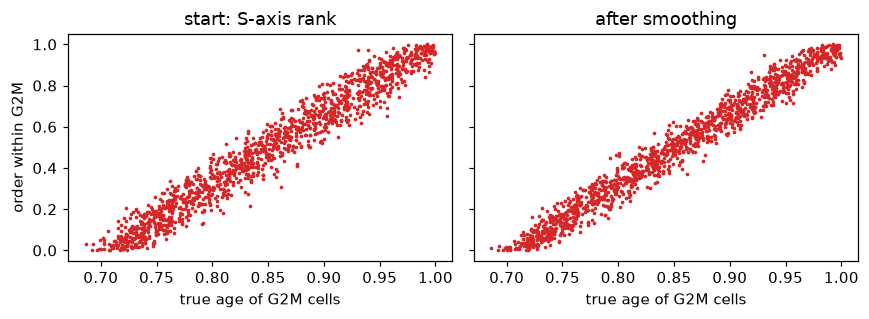

In [12]:
reference = np.flatnonzero(in_g2m)  # every simulated cell is a control, so the reference G2M cells are all of them
start_all = rank01(score[reference])
figure, axes = plt.subplots(1, 2, figsize=(8, 3), sharey=True)
for axis, values, title in zip(
    axes, (start_all, entry["order"]), ("start: S-axis rank", "after smoothing"), strict=True
):
    axis.scatter(age[reference], values, s=2, color="tab:red", rasterized=True)
    axis.set(xlabel="true age of G2M cells", title=title)
    print(f"{title}: Spearman with true age {spearman(values, age[reference]):.2f}")
axes[0].set_ylabel("order within G2M")
plt.tight_layout()
plt.show()

On all the simulated reference cells the start follows the true age at 0.98, and smoothing takes it to 0.99, since
the one informative feature is clean. Real features are noisier. On the screen, the image classifier's mitotic calls score the order,
as in [the tutorial](cell_cycle.ipynb#with-a-marker-checking-the-order), which reads the result.

project_cell_cycle: 2 ['Metadata_Plate', 'Metadata_Well'] group(s) could not be checked against the reference: {'no 4N peak': [('6', 'B01')], 'peaks moved apart': [('7', 'A02')]}


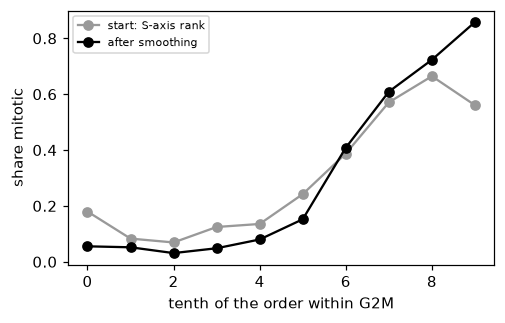

AUROC for mitotic calls, start: 0.76
AUROC for mitotic calls, after smoothing: 0.88


In [13]:
from sklearn.metrics import roc_auc_score

screen = mt.ds.aconcagua_cells()
mt.tl.dna_content(
    screen,
    dna_feature="Nuclei_Intensity_IntegratedIntensity_DAPI",
    by=("Metadata_Plate", "Metadata_Well"),
    reference="negcon",
)
mt.tl.fit_cell_cycle(screen, reference="negcon")
mt.tl.project_cell_cycle(screen)
mt.tl.phase_order(screen, phase="G2M")
real = screen.uns["mantispy"]["cell_cycle_G2M_order"]
check = ((screen.obs["cell_cycle_phase"] == "G2M") & (screen.obs["Metadata_Control_Type"] == "negcon")).to_numpy()
real_start = rank01(s_axis(screen[check], real)[0])
real_order = screen.obs.loc[check, "cell_cycle_G2M_order"].to_numpy()
is_mitotic = (screen.obs.loc[check, "Metadata_Class"] == "Mitotic").to_numpy()

figure, axis = plt.subplots(figsize=(5, 3))
deciles = np.arange(10)
for values, label, color in (
    (real_start, "start: S-axis rank", "0.6"),
    (rank01(real_order), "after smoothing", "black"),
):
    share = pd.Series(is_mitotic).groupby(np.minimum((values * 10).astype(int), 9)).mean()
    axis.plot(deciles, share.reindex(deciles), marker="o", color=color, label=label)
axis.set(xlabel="tenth of the order within G2M", ylabel="share mitotic")
axis.legend(fontsize=7)
plt.show()
print("AUROC for mitotic calls, start:", round(roc_auc_score(is_mitotic, real_start), 2))
print("AUROC for mitotic calls, after smoothing:", round(roc_auc_score(is_mitotic, real_order), 2))

Smoothing raises the AUROC for the mitotic calls from 0.76 to 0.88. The
[tutorial](cell_cycle.ipynb#with-other-channels-an-order-within-a-phase) shows what this order follows on the screen,
which is mostly gamma-H2AX.

### e. Placing every cell against the reference

The order of the reference cells stays fixed once fitted. Every cell of the phase, a control or a knockout, then gets
the mean order of its 30 nearest reference cells in the weighted space. A cell's order thus depends on the reference
and on the cell, not on the other cells placed beside it, and orders from objects placed against the same ``anchor``
can be compared. The next cell places the latest quarter of the simulated G2M cells alone, against the same anchor.

In [14]:
late = in_g2m & (age > np.quantile(age[in_g2m], 0.75))
alone = sim[late].copy()
mt.tl.phase_order(alone, model=sim.uns["mantispy"]["cell_cycle"], anchor=entry)
together = sim.obs.loc[late, "cell_cycle_G2M_order"].to_numpy()
print(
    "largest change when the late cells are placed alone:", np.abs(alone.obs["cell_cycle_G2M_order"] - together).max()
)
print("median order of the late cells:", round(float(np.median(together)), 2))

largest change when the late cells are placed alone: 0.0
median order of the late cells: 0.87


Placed alone, the late cells keep their orders exactly, at a median of 0.87. Ranked among themselves instead, they
would have spread over the whole phase.

### f. Where it worked and where it did not

The same steps run in any phase and on any features. In our tests the result depended on the phase:

- In S, DNA content already places each cell, and the order from the other features followed the true age a little
  less closely.
- In G1, with the nuclear area among the features, the order followed nuclear size, which varies far more between
  cells than it grows with age.
- In G2M, the order follows whatever trends through S, and it loses accuracy when a feature turns back in
  mitosis.

The table shows each case on the simulation, the last with tubulin falling back over the final tenth of the cycle, in
mitosis.

In [15]:
s_order = sim.copy()
mt.tl.phase_order(s_order, phase="S")
g1_order = sim.copy()
mt.tl.phase_order(g1_order, phase="G1", features=list(sim.var_names[1:]))  # nuclear area included on purpose
reversed_sim = simulate(seed=4, reverse_at=0.9)
mt.tl.dna_content(reversed_sim, dna_feature="Nuclei_Intensity_IntegratedIntensity_DNA", reference="negcon")
mt.tl.fit_cell_cycle(reversed_sim, reference="negcon")
mt.tl.project_cell_cycle(reversed_sim, by=None)
mt.tl.phase_order(reversed_sim, phase="G2M")

in_g1 = phase == "G1"
r_age = reversed_sim.obs["age"].to_numpy()
r_g2m = (reversed_sim.obs["cell_cycle_phase"] == "G2M").to_numpy()
r_order = reversed_sim.obs["cell_cycle_G2M_order"].to_numpy()
size = sim.obs["size"].to_numpy()
pd.DataFrame(
    {
        "Spearman with true age": [
            spearman(sim.obs["cell_cycle_position"][in_s], age[in_s]),
            spearman(s_order.obs["cell_cycle_S_order"][in_s], age[in_s]),
            spearman(g1_order.obs["cell_cycle_G1_order"][in_g1], age[in_g1]),
            spearman(sim.obs["cell_cycle_G2M_order"][in_g2m], age[in_g2m]),
            spearman(r_order[r_g2m], r_age[r_g2m]),
        ],
        "Spearman with cell size": [
            np.nan,
            np.nan,
            spearman(g1_order.obs["cell_cycle_G1_order"][in_g1], size[in_g1]),
            np.nan,
            np.nan,
        ],
    },
    index=[
        "S, position from DNA",
        "S, order from the other features",
        "G1, order with nuclear area",
        "G2M, tubulin keeps rising",
        "G2M, tubulin falls back in mitosis",
    ],
).round(2)

,Spearman with true age,Spearman with cell size
"S, position from DNA",0.99,NaN
"S, order from the other features",0.98,NaN
"G1, order with nuclear area",0.39,0.87
"G2M, tubulin keeps rising",0.99,NaN
"G2M, tubulin falls back in mitosis",0.69,NaN


In [16]:
mitosis = r_g2m & (r_age > 0.9)
correct = rank01(r_age[r_g2m])  # where an order that followed the true age would put each G2M cell
print("median order of cells in mitosis, where tubulin falls back:", round(float(np.median(r_order[mitosis])), 2))
print("where a correct order would put them:", round(float(np.median(correct[mitosis[r_g2m]])), 2))
print("median order of the other G2M cells:", round(float(np.median(r_order[r_g2m & ~mitosis])), 2))

median order of cells in mitosis, where tubulin falls back: 0.67
where a correct order would put them: 0.83
median order of the other G2M cells: 0.35


In S, the position from DNA follows the true age at 0.99, and the order from the other features at 0.98. In G1, the
order follows cell size at 0.87 and age at only 0.39. In G2M, with tubulin rising throughout, the order follows age at
0.99. With tubulin falling back in mitosis, it follows age at 0.69, and the cells in mitosis read at a median order of
0.67, where a correct order would put them at 0.83.

### Why it is experimental

During development the G2M order was also tested on other datasets with a marker of G2 and mitosis to check against
(results not shown here). It followed that marker on some and not on others, and none of the label-free measures we
tried, such as how well the features predict DNA content in S or how stable the order is, told which. So
{func}`~mantispy.tl.phase_order` warns on every call, and its order needs a marker or a paired modality before it is
read biologically.

## What the model cannot do

- Order cells within G1 or within G2M from DNA content. There it reports the population prior, and the order from
  other features above is an experimental addition.
- Tell resting G0 cells from G1 cells, or cells in mitosis from cells in G2, since each pair holds the same DNA.
- Describe a reference that is not growing in steady state, such as a population recovering from a block, since the
  conversion from shares to time assumes it.
- Correct a well whose stain reads differently. The well check only reports it.
- Separate every merged pair or fragment from a real cell. The shape checks catch only the clear cases.